<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/60_integracion/62_integracion_gwpca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 62 · ACP global y ACP geográficamente ponderado (GWPCA) de las capas por celda

**Autor:** Daniel (con Katalina)

**Pregunta (sección 14.5 de la ruta):** ¿qué variables de las cuatro partes se mueven juntas en la Altillanura, y esa relación es la misma en toda la región o cambia de una zona a otra?

**Entradas** (`datos/comunes/`):
- `grilla_2km_variables.csv` (cuaderno 60, DVC): todas las capas por celda.
- `grilla_2km.gpkg` (cuaderno 02, DVC) y `altillanura_municipios.gpkg` (cuaderno 01, DVC), solo para los mapas.

**Salidas** (en `modulos/integracion/resultados/` y `modulos/integracion/graficas/`):
- `62_acp_varianza.csv`, `62_acp_cargas.csv`, `62_gwpca_ancho_banda.csv`, `62_gwpca_municipio.csv`.
- `62_gwpca_celdas.csv` (DVC): una fila por celda con los puntajes del ACP global y el resultado del GWPCA.
- `62_acp_global.png`, `62_gwpca_ancho_banda.png`, `62_gwpca_mapas.png`.

**Método:**
- Las mismas 8 variables y las mismas celdas del cuaderno 61: celdas con al menos la mitad de su área en la región (`frac_celda` ≥ 0,5) y con `celda_valida`.
- Cada variable se pasa a **rangos estandarizados**. Así el ACP trabaja sobre la misma matriz de correlación de Spearman del cuaderno 61 y no lo dominan los valores extremos (por ejemplo, celdas con muchísimos focos).
- **ACP global** con scikit-learn: varianza explicada y cargas (correlación de cada variable con cada componente).
- **GWPCA** (Harris, Brunsdon y Charlton, 2011): un ACP en cada celda con pesos que bajan con la distancia (núcleo bisquare adaptativo). El ancho de banda (número de vecinos) se elige por validación cruzada dejando uno fuera, con el mismo criterio de `GWmodel::bw.gwpca`. En Python no hay un paquete maduro de GWPCA, así que se implementa con NumPy, como indica la ruta.
- Con ~34.000 celdas, el GWPCA se calibra sobre una muestra aleatoria de 4.000 celdas y luego se calcula en todas las celdas con las celdas de la muestra que tiene alrededor (la opción que prevé la ruta).
- Salidas del GWPCA por celda: % de la variación que explica el primer componente local y **variable dominante** (la de mayor carga en ese componente).

## Paso 1. Rutas y librerías
- En **Colab** clona el repo en `/content/Proyecto-ALTILLANURA`.
- En **local** toma como raíz la carpeta del repo (dos niveles arriba del cuaderno).
- `traer(ruta)` baja de DVC un archivo cuando hace falta.

In [1]:
import os, sys, re, glob, subprocess, warnings
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
EXPANSION = os.path.join(RAIZ, 'modulos', 'expansion')
CRUDOS = os.path.join(EXPANSION, 'datos', 'mapbiomas_crudos')
RESULTADOS = os.path.join(EXPANSION, 'resultados')
GRAFICAS = os.path.join(EXPANSION, 'graficas')
os.makedirs(RESULTADOS, exist_ok=True)
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

def coma(valor, decimales=1):
    return f'{valor:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.spatial import cKDTree
from sklearn.decomposition import PCA
import sklearn

RESULTADOS = os.path.join(RAIZ, 'modulos', 'integracion', 'resultados')
GRAFICAS = os.path.join(RAIZ, 'modulos', 'integracion', 'graficas')
os.makedirs(RESULTADOS, exist_ok=True)
os.makedirs(GRAFICAS, exist_ok=True)

SEMILLA = 2026
VARIABLES = {
    'focos_km2_anio': 'Focos por km² al año',
    'quema_media_anual_pct': 'Área quemada al año (%)',
    'lluvia_seca_1991_2020': 'Lluvia dic–mar (mm)',
    'lluvia_anual_1991_2020': 'Lluvia anual (mm)',
    'ph_medio': 'pH del suelo',
    'cos_medio_gkg': 'Carbono orgánico (g/kg)',
    'agro_pct_2024': '% agropecuario 2024',
    'cambio_agro_pp': 'Cambio agropecuario 2000–2024 (pp)',
}
CORTOS = {'focos_km2_anio': 'focos', 'quema_media_anual_pct': 'área quemada', 'lluvia_seca_1991_2020': 'lluvia dic–mar',
          'lluvia_anual_1991_2020': 'lluvia anual', 'ph_medio': 'pH', 'cos_medio_gkg': 'carbono orgánico',
          'agro_pct_2024': '% agropecuario 2024', 'cambio_agro_pp': 'cambio agropecuario 2000–2024'}
M_MUESTRA = 4000
VECINOS_CANDIDATOS = [25, 50, 100, 200, 400, 800]
COMPONENTES_CV = 2
BLOQUE = 500

print('Raíz del repo:', RAIZ)
print('scikit-learn', sklearn.__version__)

Raíz del repo: c:\Users\mipip\Downloads\altillanura_proyecto_\altillanura_proyecto
scikit-learn 1.8.0


## Paso 2. Datos
Se toman las celdas y las variables del cuaderno 61, para que el ACP y las correlaciones hablen de lo mismo. Las coordenadas del centro de cada celda salen de su `id_celda` (esquina inferior izquierda en km, más 1 km).

In [2]:
traer('datos/comunes/grilla_2km_variables.csv')
traer('datos/comunes/grilla_2km.gpkg')
traer('datos/comunes/altillanura_municipios.gpkg')

tabla = pd.read_csv(os.path.join(COMUNES, 'grilla_2km_variables.csv'), dtype={'id_celda': str, 'mpio_cdpmp': str})
faltan = [v for v in VARIABLES if v not in tabla.columns]
assert not faltan, f'grilla_2km_variables.csv no tiene {faltan}: vuelve a correr el cuaderno 60'

valida = tabla['celda_valida'].astype(str).str.strip().str.lower().eq('true')
d = tabla[(tabla['frac_celda'] >= 0.5) & valida].dropna(subset=list(VARIABLES)).reset_index(drop=True)
partes = d['id_celda'].str.extract(r'x(\d+)_y(\d+)').astype(int)
d['x_km'], d['y_km'] = partes[0] + 1.0, partes[1] + 1.0

rangos = d[list(VARIABLES)].rank().to_numpy(dtype=float)
Z = (rangos - rangos.mean(axis=0)) / rangos.std(axis=0)
XY = d[['x_km', 'y_km']].to_numpy(dtype=float)
N = len(d)

print(f'Celdas analizadas: {N:,} de {len(tabla):,} (frac_celda ≥ 0,5, celda_valida y sin datos faltantes)')
print(d['mpio_cnmbr'].value_counts().to_string())

Celdas analizadas: 33,799 de 34,763 (frac_celda ≥ 0,5, celda_valida y sin datos faltantes)
mpio_cnmbr
CUMARIBO          16273
LA PRIMAVERA       4595
PUERTO GAITÁN      4334
MAPIRIPÁN          2984
PUERTO CARREÑO     2967
PUERTO LÓPEZ       1733
SANTA ROSALÍA       913


## Paso 3. ACP global
Con las variables en rangos estandarizados, cada componente es una combinación de las 8 variables. La **carga** de una variable es su correlación con el componente: cerca de ±1, la variable pesa mucho; cerca de 0, casi nada. Se retienen para leer los componentes con valor propio mayor que 1 (criterio de Kaiser). El signo de cada componente se fija para que su carga más grande sea positiva.

In [3]:
acp = PCA(n_components=len(VARIABLES), random_state=SEMILLA).fit(Z)
valores = acp.explained_variance_
cargas = acp.components_.T * np.sqrt(valores)
signos = np.sign(cargas[np.abs(cargas).argmax(axis=0), np.arange(cargas.shape[1])])
cargas = cargas * signos
puntajes = acp.transform(Z) * signos

COMPONENTES = [f'CP{k + 1}' for k in range(len(VARIABLES))]
varianza = pd.DataFrame({'componente': COMPONENTES, 'valor_propio': valores,
                         'pct_varianza': acp.explained_variance_ratio_ * 100,
                         'pct_acumulado': np.cumsum(acp.explained_variance_ratio_) * 100})
tabla_cargas = pd.DataFrame(cargas[:, :3], index=list(VARIABLES), columns=COMPONENTES[:3])
tabla_cargas.insert(0, 'descripcion', list(VARIABLES.values()))
varianza.round(4).to_csv(os.path.join(RESULTADOS, '62_acp_varianza.csv'), index=False)
tabla_cargas.round(4).to_csv(os.path.join(RESULTADOS, '62_acp_cargas.csv'), index_label='variable')
print(varianza.round(2).to_string(index=False))
print(f'\nComponentes con valor propio > 1: {(valores > 1).sum()}')
print(tabla_cargas.round(2).to_string())

def resumen_componente(j, umbral=0.5, maximo=None):
    ordenadas = tabla_cargas[COMPONENTES[j]].sort_values(key=np.abs, ascending=False)
    fuertes = ordenadas[ordenadas.abs() >= umbral]
    if fuertes.empty:
        fuertes = ordenadas.iloc[:2]
    return ', '.join(f'{CORTOS[v]} ({"+" if c > 0 else "−"})' for v, c in fuertes.iloc[:maximo].items())

TEXTO_CP = {j: resumen_componente(j) for j in range(2)}
TITULO_CP1 = resumen_componente(0, maximo=4)
for j in range(2):
    print(f'{COMPONENTES[j]} ({coma(varianza.pct_varianza.iloc[j])} %): {TEXTO_CP[j]}')

componente  valor_propio  pct_varianza  pct_acumulado
       CP1          4.05         50.66          50.66
       CP2          1.28         15.95          66.60
       CP3          1.02         12.78          79.38
       CP4          0.81         10.12          89.50
       CP5          0.35          4.36          93.86
       CP6          0.25          3.13          96.99
       CP7          0.15          1.86          98.85
       CP8          0.09          1.15         100.00

Componentes con valor propio > 1: 3
                                               descripcion   CP1   CP2   CP3
focos_km2_anio                        Focos por km² al año  0.79  0.02  0.31
quema_media_anual_pct              Área quemada al año (%)  0.83 -0.19  0.27
lluvia_seca_1991_2020                  Lluvia dic–mar (mm) -0.81  0.29  0.43
lluvia_anual_1991_2020                   Lluvia anual (mm) -0.69  0.21  0.62
ph_medio                                      pH del suelo  0.83 -0.30  0.20
cos_medio_gkg  

La figura muestra a la izquierda cuánto explica cada componente, en el centro las cargas de los tres primeros y a la derecha el puntaje del primer componente en cada celda.

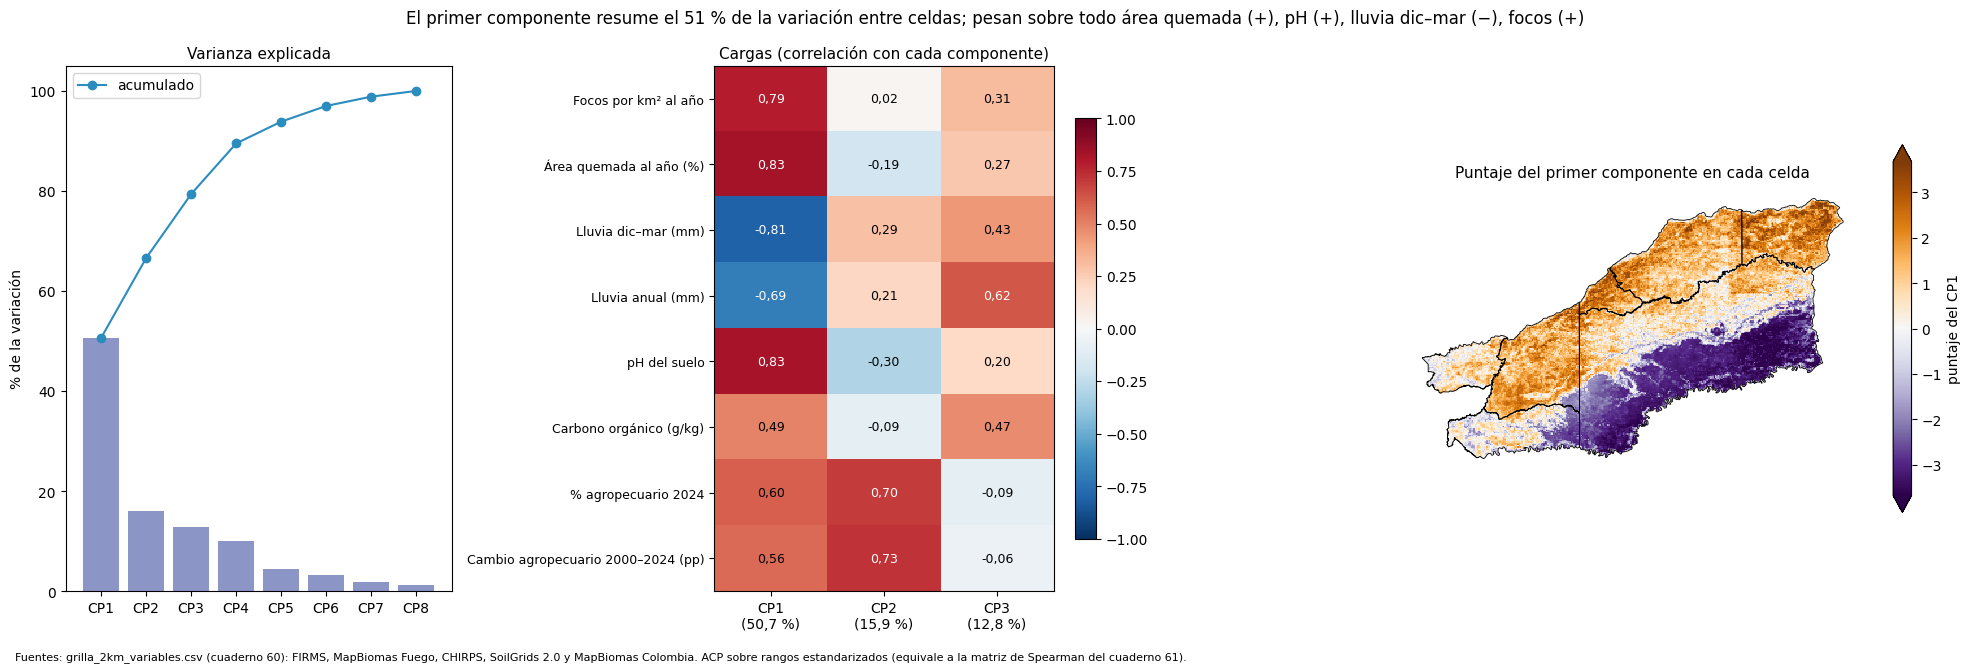

In [4]:
grilla = gpd.read_file(os.path.join(COMUNES, 'grilla_2km.gpkg')).to_crs(9377)
mpios = gpd.read_file(os.path.join(COMUNES, 'altillanura_municipios.gpkg')).to_crs(9377)
d['cp1_global'], d['cp2_global'] = puntajes[:, 0], puntajes[:, 1]
mapa = grilla[['id_celda', 'geometry']].merge(d, on='id_celda', how='inner')

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), gridspec_kw={'width_ratios': [1, 1.1, 1.5]})
ax = axes[0]
ax.bar(varianza['componente'], varianza['pct_varianza'], color='#8c96c6')
ax.plot(varianza['componente'], varianza['pct_acumulado'], color='#2b8cbe', marker='o', label='acumulado')
ax.set_ylabel('% de la variación')
ax.set_title('Varianza explicada', fontsize=11)
ax.legend()

ax = axes[1]
im = ax.imshow(tabla_cargas[COMPONENTES[:3]].to_numpy(), cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(3), [f'{c}\n({coma(p)} %)' for c, p in zip(COMPONENTES[:3], varianza['pct_varianza'][:3])])
ax.set_yticks(range(len(VARIABLES)), list(VARIABLES.values()), fontsize=9)
for i in range(len(VARIABLES)):
    for j in range(3):
        valor = tabla_cargas[COMPONENTES[j]].iloc[i]
        ax.text(j, i, coma(valor, 2), ha='center', va='center', fontsize=9, color='white' if abs(valor) > 0.6 else 'black')
ax.set_title('Cargas (correlación con cada componente)', fontsize=11)
fig.colorbar(im, ax=ax, shrink=0.8)

ax = axes[2]
limite = np.nanpercentile(np.abs(mapa['cp1_global']), 98)
mapa.plot(ax=ax, column='cp1_global', cmap='PuOr_r', vmin=-limite, vmax=limite, linewidth=0, legend=True,
          legend_kwds={'shrink': 0.7, 'label': 'puntaje del CP1'})
mpios.boundary.plot(ax=ax, color='black', linewidth=0.6)
ax.set_title('Puntaje del primer componente en cada celda', fontsize=11)
ax.set_axis_off()

fig.suptitle(f'El primer componente resume el {coma(varianza.pct_varianza.iloc[0], 0)} % de la variación entre celdas; pesan sobre todo {TITULO_CP1}', fontsize=12)
fig.text(0.01, -0.02, 'Fuentes: grilla_2km_variables.csv (cuaderno 60): FIRMS, MapBiomas Fuego, CHIRPS, SoilGrids 2.0 y MapBiomas Colombia. '
         'ACP sobre rangos estandarizados (equivale a la matriz de Spearman del cuaderno 61).', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '62_acp_global.png'), dpi=150, bbox_inches='tight')
plt.show()

## Paso 4. GWPCA: ancho de banda por validación cruzada
En cada celda se calcula un ACP con las celdas vecinas de la muestra, con pesos bisquare: peso 1 en la celda y 0 desde el vecino número *k* en adelante. Para elegir *k* se deja fuera cada celda de la muestra, se calcula el ACP local con sus vecinas, se reconstruye la celda con los 2 primeros componentes locales y se suma el error. Se elige el *k* con el menor error. La tabla también da la distancia mediana hasta el vecino *k*, que es el radio real de cada ACP local.

 vecinos  distancia_mediana_km  error_cv
      25                 17.09   2727.42
      50                 24.08   2747.47
     100                 34.00   2946.76
     200                 48.37   3321.32
     400                 70.94   3852.78
     800                108.07   4711.21

Ancho de banda elegido: 25 vecinos de la muestra (radio mediano de 17 km) · está en el borde de los candidatos: el error podría bajar más allá


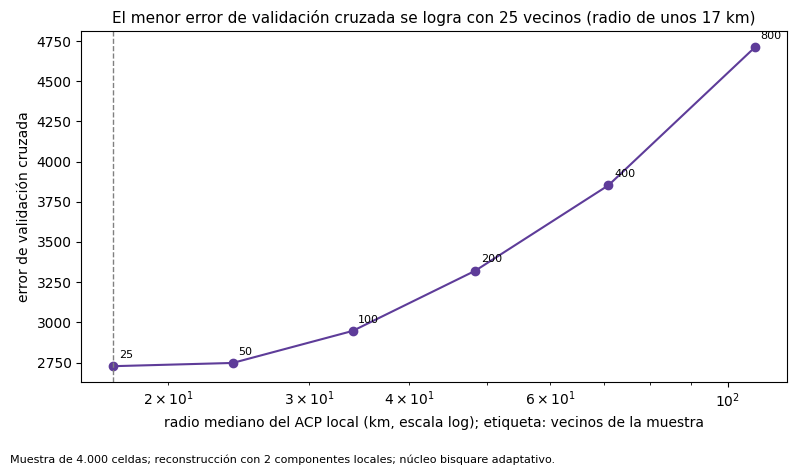

In [5]:
def pesos_bisquare(distancias):
    banda = distancias[:, -1:]
    return np.clip(1 - (distancias / banda) ** 2, 0, None) ** 2

def acp_local(valores_vecinos, pesos):
    suma = pesos.sum(axis=1, keepdims=True)
    media = np.einsum('ck,ckp->cp', pesos, valores_vecinos) / suma
    centrados = valores_vecinos - media[:, None, :]
    covarianza = np.einsum('ck,ckp,ckq->cpq', pesos, centrados, centrados) / suma[:, :, None]
    valores_propios, vectores = np.linalg.eigh(covarianza)
    return media, np.clip(valores_propios[:, ::-1], 0, None), vectores[:, :, ::-1]

rng = np.random.default_rng(SEMILLA)
m = min(M_MUESTRA, N)
muestra = np.sort(rng.choice(N, m, replace=False))
Zm, XYm = Z[muestra], XY[muestra]
arbol = cKDTree(XYm)

filas = []
for k in [v for v in VECINOS_CANDIDATOS if v + 2 <= m]:
    dist, idx = arbol.query(XYm, k=k + 2)
    dist, idx = dist[:, 1:], idx[:, 1:]
    pesos = pesos_bisquare(dist)
    error = 0.0
    for inicio in range(0, m, BLOQUE):
        c = slice(inicio, inicio + BLOQUE)
        media, _, vectores = acp_local(Zm[idx[c]], pesos[c])
        V = vectores[:, :, :COMPONENTES_CV]
        resto = Zm[c] - media
        proyeccion = np.einsum('cpq,cq->cp', V, np.einsum('cpq,cp->cq', V, resto))
        error += float(((resto - proyeccion) ** 2).sum())
    filas.append({'vecinos': k, 'distancia_mediana_km': float(np.median(dist[:, -1])), 'error_cv': error})
ancho = pd.DataFrame(filas)
K = int(ancho.loc[ancho['error_cv'].idxmin(), 'vecinos'])
RADIO_KM = float(ancho.loc[ancho['vecinos'] == K, 'distancia_mediana_km'].iloc[0])
EN_BORDE = K in (ancho['vecinos'].min(), ancho['vecinos'].max())
ancho.round(4).to_csv(os.path.join(RESULTADOS, '62_gwpca_ancho_banda.csv'), index=False)
print(ancho.round(2).to_string(index=False))
print(f'\nAncho de banda elegido: {K} vecinos de la muestra (radio mediano de {coma(RADIO_KM, 0)} km)'
      + (' · está en el borde de los candidatos: el error podría bajar más allá' if EN_BORDE else ''))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ancho['distancia_mediana_km'], ancho['error_cv'], marker='o', color='#5e3c99')
for _, f in ancho.iterrows():
    ax.annotate(f'{int(f.vecinos)}', (f.distancia_mediana_km, f.error_cv), textcoords='offset points', xytext=(4, 6), fontsize=8)
ax.axvline(RADIO_KM, color='grey', linestyle='--', linewidth=1)
ax.set_xscale('log')
ax.set_xlabel('radio mediano del ACP local (km, escala log); etiqueta: vecinos de la muestra')
ax.set_ylabel('error de validación cruzada')
ax.set_title(f'El menor error de validación cruzada se logra con {K} vecinos (radio de unos {coma(RADIO_KM, 0)} km)', fontsize=11)
fig.text(0.01, -0.04, f'Muestra de {coma(m, 0)} celdas; reconstrucción con {COMPONENTES_CV} componentes locales; núcleo bisquare adaptativo.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '62_gwpca_ancho_banda.png'), dpi=150, bbox_inches='tight')
plt.show()

## Paso 5. GWPCA en toda la grilla
Con el ancho de banda elegido se calcula el ACP local en cada celda analizada, usando las celdas de la muestra que tiene alrededor. De cada ACP local se guardan:
- el **% de la variación** que explica el primer componente local (y los dos primeros juntos): alto significa que, en esa zona, las variables se mueven casi todas juntas;
- la **variable dominante**: la de mayor carga absoluta en el primer componente local. Muestra qué variable organiza la variación en cada zona.

Cómo leerlo: si el primer componente local explica bastante menos que el global, la estructura del ACP global viene sobre todo del contraste entre zonas (por ejemplo, norte frente a sur) y no de una relación que se repita dentro de cada zona.

In [6]:
dist, idx = arbol.query(XY, k=K + 1)
pesos = pesos_bisquare(dist)
pct_1, pct_12, dominante, carga = (np.empty(N), np.empty(N), np.empty(N, dtype=int), np.empty(N))
for inicio in range(0, N, BLOQUE):
    c = slice(inicio, inicio + BLOQUE)
    _, valores_locales, vectores = acp_local(Zm[idx[c]], pesos[c])
    total = valores_locales.sum(axis=1)
    pct_1[c] = valores_locales[:, 0] / total * 100
    pct_12[c] = valores_locales[:, :2].sum(axis=1) / total * 100
    primero = np.abs(vectores[:, :, 0])
    dominante[c] = primero.argmax(axis=1)
    carga[c] = primero.max(axis=1)

NOMBRES = list(VARIABLES)
d['pct_varianza_cp1_local'] = pct_1
d['pct_varianza_cp1_cp2_local'] = pct_12
d['variable_dominante'] = [NOMBRES[k] for k in dominante]
d['carga_dominante'] = carga
salida = d[['id_celda', 'mpio_cdpmp', 'mpio_cnmbr', 'cp1_global', 'cp2_global', 'pct_varianza_cp1_local',
            'pct_varianza_cp1_cp2_local', 'variable_dominante', 'carga_dominante']].rename(columns={'mpio_cnmbr': 'municipio'})
salida.round(4).to_csv(os.path.join(RESULTADOS, '62_gwpca_celdas.csv'), index=False)

grupos = salida.groupby('municipio')
por_mpio = pd.DataFrame({'celdas': grupos.size(),
                         'mediana_pct_cp1_local': grupos['pct_varianza_cp1_local'].median(),
                         'variable_mas_frecuente': grupos['variable_dominante'].agg(lambda s: s.value_counts().index[0]),
                         'pct_celdas_variable': grupos['variable_dominante'].agg(lambda s: s.value_counts(normalize=True).iloc[0] * 100)})
por_mpio = por_mpio.sort_values('celdas', ascending=False)
por_mpio.round(2).to_csv(os.path.join(RESULTADOS, '62_gwpca_municipio.csv'))

GLOBAL_1 = float(varianza.pct_varianza.iloc[0])
P10, P90 = np.percentile(pct_1, [10, 90])
reparto = salida['variable_dominante'].value_counts(normalize=True) * 100
print(f'% de la variación del primer componente local: mediana {coma(np.median(pct_1))} %, '
      f'P10–P90 {coma(P10)}–{coma(P90)} % (global: {coma(GLOBAL_1)} %)')
print('\nVariable dominante (% de las celdas):')
print(reparto.rename(index=CORTOS).round(1).to_string())
print('\nPor municipio:')
print(por_mpio.assign(variable_mas_frecuente=por_mpio['variable_mas_frecuente'].map(CORTOS)).round(1).to_string())

% de la variación del primer componente local: mediana 56,4 %, P10–P90 43,3–74,7 % (global: 50,7 %)

Variable dominante (% de las celdas):
variable_dominante
cambio agropecuario 2000–2024    31.4
carbono orgánico                 26.8
% agropecuario 2024              13.8
focos                            13.5
área quemada                      8.0
pH                                5.2
lluvia anual                      1.4

Por municipio:
                celdas  mediana_pct_cp1_local         variable_mas_frecuente  pct_celdas_variable
municipio                                                                                        
CUMARIBO         16273                   58.5               carbono orgánico                 42.6
LA PRIMAVERA      4595                   52.6            % agropecuario 2024                 34.2
PUERTO GAITÁN     4334                   54.6  cambio agropecuario 2000–2024                 38.3
MAPIRIPÁN         2984                   58.8  cambio agropecuario 200

## Paso 6. Mapas del GWPCA

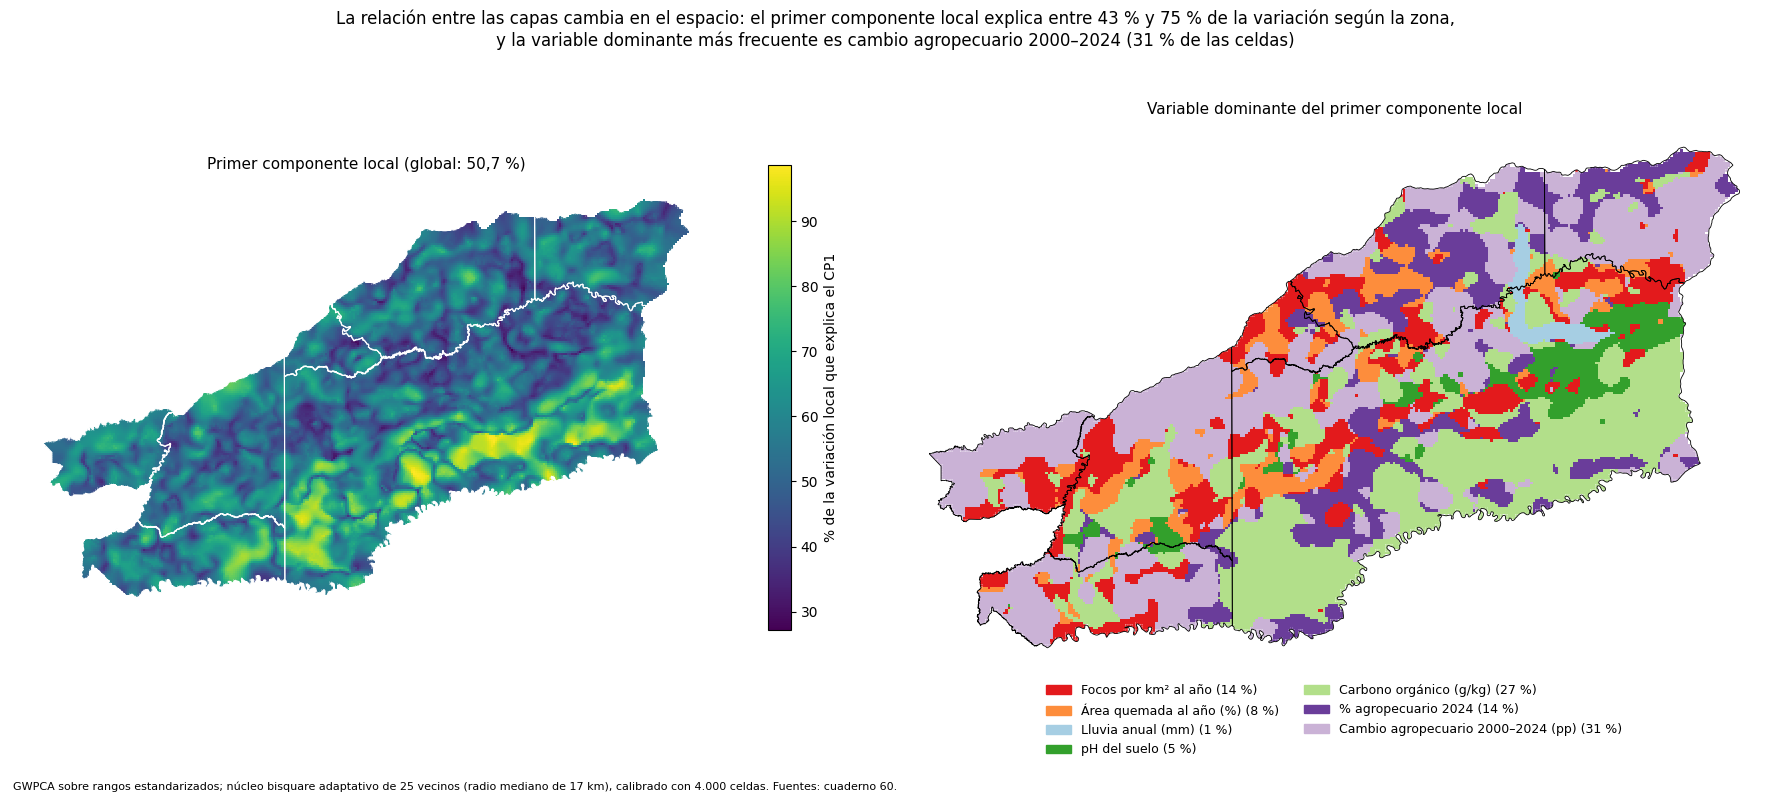

In [7]:
mapa = grilla[['id_celda', 'geometry']].merge(salida, on='id_celda', how='inner')
COLORES = dict(zip(VARIABLES, ['#e31a1c', '#fd8d3c', '#1f78b4', '#a6cee3', '#33a02c', '#b2df8a', '#6a3d9a', '#cab2d6']))

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
ax = axes[0]
mapa.plot(ax=ax, column='pct_varianza_cp1_local', cmap='viridis', linewidth=0, legend=True,
          legend_kwds={'shrink': 0.7, 'label': '% de la variación local que explica el CP1'})
mpios.boundary.plot(ax=ax, color='white', linewidth=0.8)
ax.set_title(f'Primer componente local (global: {coma(GLOBAL_1)} %)', fontsize=11)
ax.set_axis_off()

ax = axes[1]
manijas = []
for variable, color in COLORES.items():
    sub = mapa[mapa['variable_dominante'] == variable]
    if len(sub):
        sub.plot(ax=ax, color=color, linewidth=0)
        manijas.append(Patch(color=color, label=f'{VARIABLES[variable]} ({coma(reparto.get(variable, 0), 0)} %)'))
mpios.boundary.plot(ax=ax, color='black', linewidth=0.6)
ax.legend(handles=manijas, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False)
ax.set_title('Variable dominante del primer componente local', fontsize=11)
ax.set_axis_off()

PRINCIPAL = reparto.index[0]
fig.suptitle(f'La relación entre las capas cambia en el espacio: el primer componente local explica entre {coma(P10, 0)} % y {coma(P90, 0)} % '
             f'de la variación según la zona,\ny la variable dominante más frecuente es {CORTOS[PRINCIPAL]} ({coma(reparto.iloc[0], 0)} % de las celdas)',
             fontsize=12)
fig.text(0.01, -0.06, f'GWPCA sobre rangos estandarizados; núcleo bisquare adaptativo de {K} vecinos (radio mediano de {coma(RADIO_KM, 0)} km), '
         f'calibrado con {coma(m, 0)} celdas. Fuentes: cuaderno 60.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '62_gwpca_mapas.png'), dpi=150, bbox_inches='tight')
plt.show()

## Límites
- Es un análisis **descriptivo**: muestra qué variables van juntas y dónde, no qué causa qué. No se hace la prueba de Monte Carlo de no estacionariedad de GWmodel, así que las diferencias entre zonas no tienen un valor p.
- Al usar rangos, el ACP describe relaciones monótonas (como Spearman), no la magnitud exacta de las variables.
- Hay dos variables de lluvia y dos de expansión muy correlacionadas entre sí; pesan más en el ACP que una variable sola.
- Varias capas son productos modelados y suavizados (SoilGrids, CHIRPS de ~5 km): parte de la estructura local puede venir de ese suavizado.
- Las variables muy suaves en el espacio (lluvia, pH) cambian poco dentro de cada zona, así que casi nunca son la variable dominante local. Eso no quiere decir que no importen: su papel está en el contraste entre zonas, que recoge el ACP global.
- El GWPCA se calibra con una muestra de 4.000 celdas; el resultado de cada celda depende de las celdas de la muestra que tiene alrededor. Si dos cargas locales son parecidas, la variable dominante de esa celda es poco estable (`carga_dominante` lo indica).

## Resumen para el informe

In [8]:
print(f'Celdas: {coma(N, 0)}; variables: {", ".join(CORTOS.values())} (rangos estandarizados, igual que en el cuaderno 61).')
print(f'ACP global: el CP1 explica el {coma(varianza.pct_varianza.iloc[0])} % y el CP2 el {coma(varianza.pct_varianza.iloc[1])} % '
      f'(acumulado {coma(varianza.pct_acumulado.iloc[1])} %); {(valores > 1).sum()} componentes con valor propio > 1.')
print(f'  CP1: {TEXTO_CP[0]}.')
print(f'  CP2: {TEXTO_CP[1]}.')
print(f'GWPCA: ancho de banda de {K} vecinos de la muestra (radio mediano de {coma(RADIO_KM, 0)} km) por validación cruzada'
      + (', en el borde de los candidatos' if EN_BORDE else '') + '.')
print(f'  El primer componente local explica entre {coma(P10)} % y {coma(P90)} % (P10–P90; mediana {coma(np.median(pct_1))} %), frente a {coma(GLOBAL_1)} % en el ACP global.')
print('  Variable dominante:', '; '.join(f'{CORTOS[v]} {coma(p, 0)} %' for v, p in reparto.items()) + '.')
for municipio, f in por_mpio.iterrows():
    print(f'  {municipio.title()}: CP1 local {coma(f.mediana_pct_cp1_local, 0)} %; domina {CORTOS[f.variable_mas_frecuente]} '
          f'en el {coma(f.pct_celdas_variable, 0)} % de sus celdas.')

Celdas: 33.799; variables: focos, área quemada, lluvia dic–mar, lluvia anual, pH, carbono orgánico, % agropecuario 2024, cambio agropecuario 2000–2024 (rangos estandarizados, igual que en el cuaderno 61).
ACP global: el CP1 explica el 50,7 % y el CP2 el 15,9 % (acumulado 66,6 %); 3 componentes con valor propio > 1.
  CP1: área quemada (+), pH (+), lluvia dic–mar (−), focos (+), lluvia anual (−), % agropecuario 2024 (+), cambio agropecuario 2000–2024 (+).
  CP2: cambio agropecuario 2000–2024 (+), % agropecuario 2024 (+).
GWPCA: ancho de banda de 25 vecinos de la muestra (radio mediano de 17 km) por validación cruzada, en el borde de los candidatos.
  El primer componente local explica entre 43,3 % y 74,7 % (P10–P90; mediana 56,4 %), frente a 50,7 % en el ACP global.
  Variable dominante: cambio agropecuario 2000–2024 31 %; carbono orgánico 27 %; % agropecuario 2024 14 %; focos 14 %; área quemada 8 %; pH 5 %; lluvia anual 1 %.
  Cumaribo: CP1 local 58 %; domina carbono orgánico en el 43 